# Expense Tracker: Real Bank Transaction Analysis

**Goal:** Build an expense tracker on real bank data. It categorizes every transaction, tracks spending by category and month, flags unusual increases, finds avoidable costs, forecasts upcoming spending, and recommends savings.

**Data:** The [Berka dataset](https://github.com/jlacko/berka-dataset), with **real, anonymized transactions from a Czech bank** released for the PKDD'99 data mining challenge. This project uses a **random sample of 500 accounts** (fixed seed, so it's reproducible): **117,560 transactions** from 1993–1998, with the main analysis on the **12 months of 1998 (35,911 transactions)**.

Amounts are in Czech crowns (CZK). For context, 1998 averaged about **32 CZK per US dollar**.

**Sections**
1. Build the tracker database (translate + categorize)
2. Where the money goes: 12 months of 1998
3. Spending patterns over time
4. Month-over-month increases
5. Avoidable costs: fees and penalty interest
6. Income vs. spending
7. Forecasting monthly spending
8. Savings scenarios
9. Key findings

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from analysis import backtest, flag_increases
from tracker import CZK_PER_USD, build_database, monthly_spending, query

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
PALETTE = {"Cash Withdrawals": "#264653", "Household Bills": "#2a9d8f", "Transfers Out": "#8ab17d",
           "Loan Payments": "#e9c46a", "Card Purchases": "#f4a261", "Insurance": "#e76f51",
           "Bank Fees": "#9b2226", "Penalty Interest": "#6d597a"}
czk = mtick.StrMethodFormatter("{x:,.0f}")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

def usd(x):
    return f"${x / CZK_PER_USD:,.0f}"


## 1. Build the tracker database

`tracker.py build` loads the raw bank export, parses dates (stored as `YYMMDD`), translates the bank's Czech codes (`SIPO` = household bills, `SANKC. UROK` = penalty interest, `VYBER KARTOU` = card purchase), and categorizes every transaction with the rules in `config/categories.json`. Results go into SQLite, indexed by account and date.

Each category belongs to a group:
- **Income:** deposits, transfers in, pensions, interest
- **Essential:** household bills, insurance, loan payments
- **Discretionary:** card purchases
- **Cash & Transfers:** cash withdrawals and transfers to other banks. These have no purpose code, so they aren't guessed into a category.
- **Avoidable:** bank statement fees and penalty interest

In [2]:
n_tx, n_acc = build_database()
tx = query("SELECT * FROM transactions")
tx["date"] = pd.to_datetime(tx["date"])
tx["month"] = tx["date"].dt.to_period("M")
accounts = query("SELECT * FROM accounts")

print(f"{n_tx:,} transactions across {n_acc} accounts, {tx['date'].min():%b %Y} to {tx['date'].max():%b %Y}")
print(f"Categorized: {(tx['category'] != 'Uncategorized').mean():.1%}")
(tx.groupby(["grp", "category"])
   .agg(transactions=("trans_id", "count"), total_czk=("amount", "sum"))
   .round(0))

117,560 transactions across 500 accounts, Jan 1993 to Dec 1998
Categorized: 100.0%


transactions    total_czk
grp              category                                   
Avoidable        Bank Fees                17324     296977.0
                 Penalty Interest           122       3739.0
Cash & Transfers Cash Withdrawals         30849  261385583.0
                 Transfers Out             6924   14977184.0
Discretionary    Card Purchases             788    1678900.0
Essential        Household Bills          13106   54673233.0
                 Insurance                 1732    2595305.0
                 Loan Payments             1594    6432758.0
Income           Cash Deposits            17918  272067414.0
                 Interest Earned          20379    3070254.0
                 Pension                   3240   17478263.0
                 Transfers In              3584   71172691.0

## 2. Where the money goes: 12 months of 1998

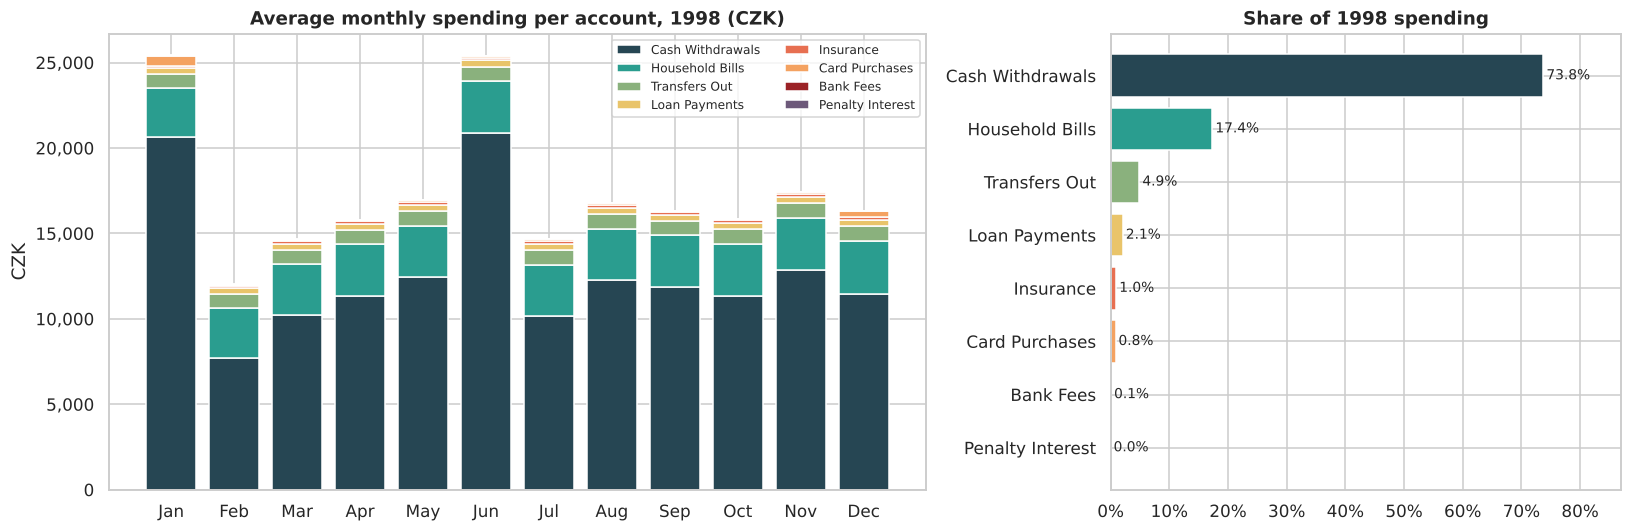

Average account spent 17,308 CZK/month (~$536) in 1998


,share
category,
Cash Withdrawals,0.738
Household Bills,0.174
Transfers Out,0.049
Loan Payments,0.021
Insurance,0.010
Card Purchases,0.008
Bank Fees,0.001
Penalty Interest,0.000


In [3]:
y98 = tx[(tx["date"].dt.year == 1998)]
spend98 = y98[y98["signed_amount"] < 0]
active98 = y98.groupby("month")["account_id"].nunique()
monthly98 = monthly_spending(year=1998)
per_account = monthly98.div(active98.values, axis=0)
order = per_account.sum().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(per_account))
labels = pd.PeriodIndex(per_account.index, freq="M").strftime("%b")
for cat in order:
    axes[0].bar(labels, per_account[cat], bottom=bottom, color=PALETTE[cat], label=cat)
    bottom += per_account[cat].values
axes[0].yaxis.set_major_formatter(czk)
axes[0].set(title="Average monthly spending per account, 1998 (CZK)", ylabel="CZK")
axes[0].legend(fontsize=8, ncol=2, loc="upper right")

totals = spend98.groupby("category")["amount"].sum().reindex(order)
share = totals / totals.sum()
axes[1].barh(order[::-1], share[order[::-1]], color=[PALETTE[c] for c in order[::-1]])
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
for y_, v in enumerate(share[order[::-1]]):
    axes[1].text(v + 0.005, y_, f"{v:.1%}", va="center", fontsize=9)
axes[1].set(title="Share of 1998 spending", xlim=(0, share.max() * 1.18))
fig.tight_layout()
save(fig, "01_spending_1998")
plt.show()

avg_month = per_account.sum(axis=1).mean()
print(f"Average account spent {avg_month:,.0f} CZK/month (~{usd(avg_month)}) in 1998")
share.round(3).to_frame("share")

## 3. Spending patterns over time

Accounts were opened gradually from 1993 to 1997, so raw totals would just reflect the bank growing. To compare fairly across time, everything below is **per active account**.

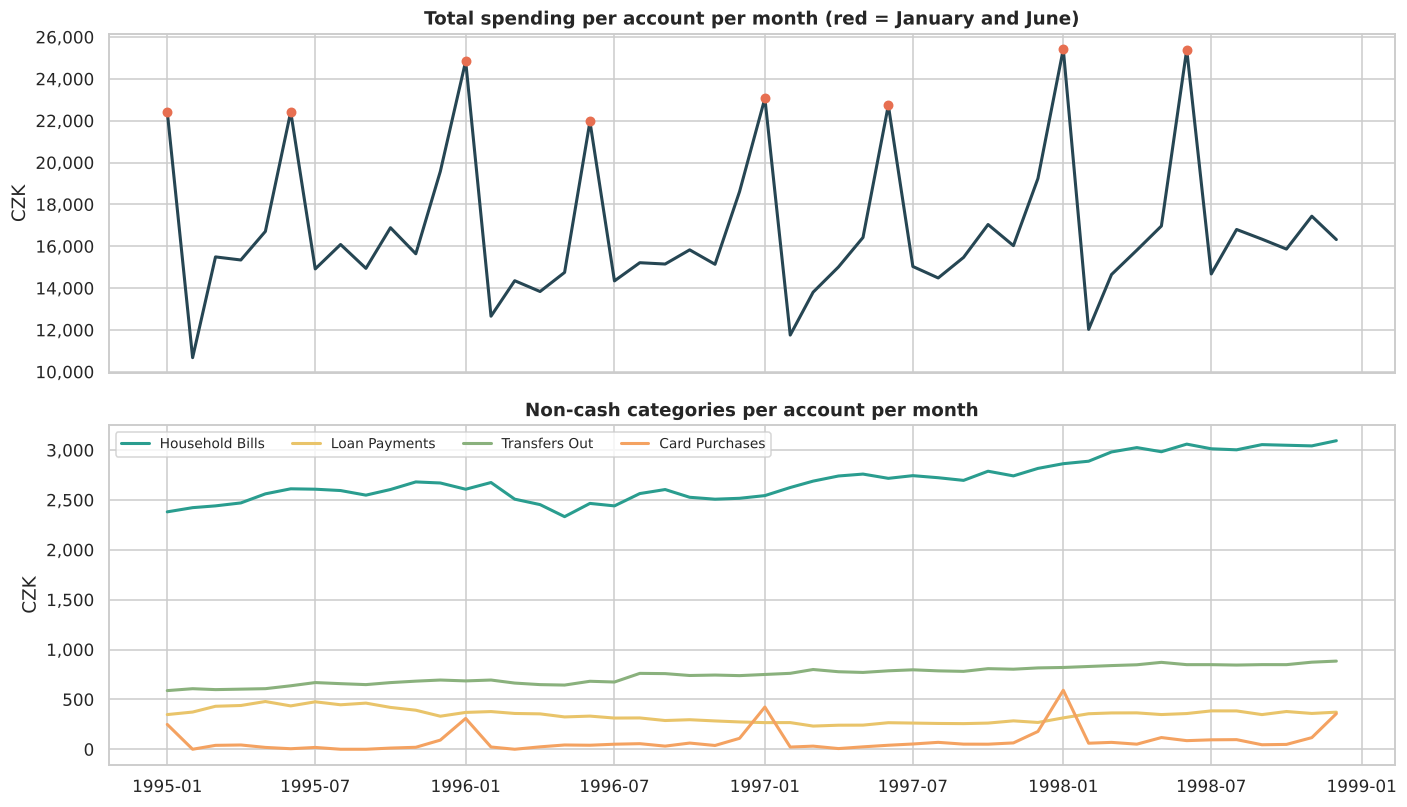

January and June spending is 53% higher than other months on average
Household bills per account: 2,549 CZK/month in 1995 -> 3,004 in 1998 (+18%)
Card purchases in December vs. other months (1998): 4.5x


In [4]:
active = tx.groupby("month")["account_id"].nunique()
spend_all = tx[tx["signed_amount"] < 0].groupby(["month", "category"])["amount"].sum().unstack(fill_value=0)
per_acct_all = spend_all.div(active, axis=0).loc["1995-01":]
total_per_acct = per_acct_all.sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
x = per_acct_all.index.to_timestamp()
axes[0].plot(x, total_per_acct, color="#264653", lw=2)
for ts, v in zip(x, total_per_acct):
    if ts.month in (1, 6):
        axes[0].scatter(ts, v, color="#e76f51", zorder=3, s=30)
axes[0].yaxis.set_major_formatter(czk)
axes[0].set(title="Total spending per account per month (red = January and June)", ylabel="CZK")
for cat in ["Household Bills", "Loan Payments", "Transfers Out", "Card Purchases"]:
    axes[1].plot(x, per_acct_all[cat], lw=2, color=PALETTE[cat], label=cat)
axes[1].yaxis.set_major_formatter(czk)
axes[1].set(title="Non-cash categories per account per month", ylabel="CZK")
axes[1].legend(ncol=4, fontsize=9, loc="upper left")
fig.tight_layout()
save(fig, "02_patterns_over_time")
plt.show()

season = total_per_acct.groupby(total_per_acct.index.month).mean()
spike = season[[1, 6]].mean() / season.drop([1, 6]).mean() - 1
bills = per_acct_all["Household Bills"]
print(f"January and June spending is {spike:.0%} higher than other months on average")
print(f"Household bills per account: {bills.loc['1995-01':'1995-12'].mean():,.0f} CZK/month in 1995 -> "
      f"{bills.loc['1998-01':'1998-12'].mean():,.0f} in 1998 (+{bills.loc['1998'].mean() / bills.loc['1995'].mean() - 1:.0%})")
print(f"Card purchases in December vs. other months (1998): "
      f"{per_acct_all.loc['1998-12', 'Card Purchases'] / per_acct_all.loc['1998-02':'1998-11', 'Card Purchases'].mean():.1f}x")

## 4. Month-over-month increases

Each account's **total monthly spending** in 1998 is compared with the month before (December 1997 is used as the baseline for January). A month is flagged as a **spike** when spending **at least doubles AND rises by at least 10,000 CZK (~$310)**. Requiring both keeps small accounts' noise out and focuses on months that would actually strain a budget. For each spike, the category that grew the most is recorded as the driver.

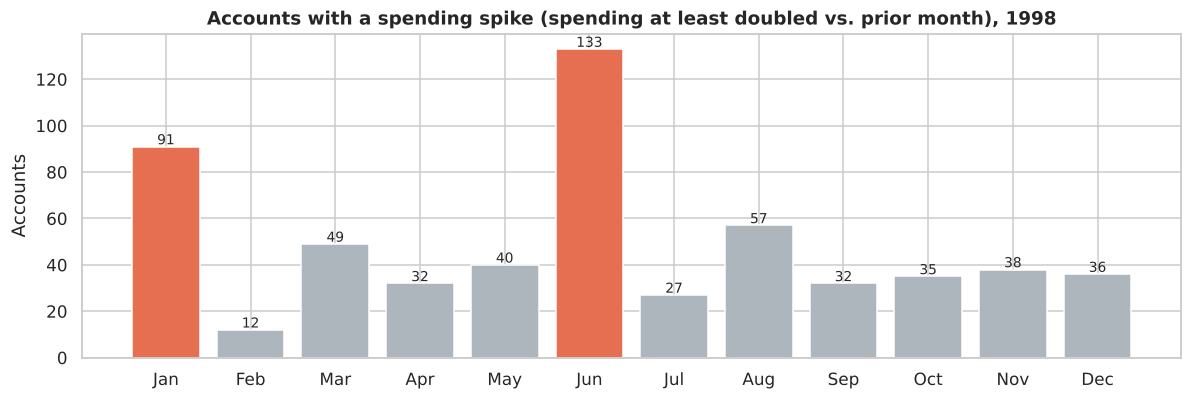

297 of 498 accounts (60%) had at least one spike month in 1998
Median spike size: +24,300 CZK (~$752)
Spikes in January or June: 38% of all spikes


,share_of_spikes_driven_by
driver,
Cash Withdrawals,0.983
Household Bills,0.009
Card Purchases,0.005
Transfers Out,0.002
Loan Payments,0.002


In [5]:
window = pd.period_range("1997-12", "1998-12", freq="M")
spend_win = tx[(tx["signed_amount"] < 0) & tx["month"].isin(window)]
acct_cat = spend_win.groupby(["account_id", "month", "category"])["amount"].sum().unstack(fill_value=0)
acct_total = acct_cat.sum(axis=1).unstack(fill_value=0).reindex(columns=window, fill_value=0)

rows = []
for acct, row in acct_total.iterrows():
    f = flag_increases(row.to_frame("Total"), min_pct=1.0, min_amount=10_000)
    for _, r in f.iterrows():
        cats = acct_cat.loc[acct]
        prev_m = r["month"] - 1
        cur = cats.loc[r["month"]] if r["month"] in cats.index else 0
        prev = cats.loc[prev_m] if prev_m in cats.index else 0
        rows.append({"account_id": acct, "month": r["month"], "previous": r["previous"],
                     "current": r["current"], "change": r["change"], "driver": (cur - prev).idxmax()})
flags = pd.DataFrame(rows)

n_active = spend98["account_id"].nunique()
by_month = flags.groupby("month").size().reindex(pd.period_range("1998-01", "1998-12", freq="M"), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(by_month.index.strftime("%b"), by_month.values,
       color=["#e76f51" if p.month in (1, 6) else "#adb5bd" for p in by_month.index])
for x_, v in enumerate(by_month.values):
    ax.text(x_, v + 1, str(v), ha="center", fontsize=9)
ax.set(title="Accounts with a spending spike (spending at least doubled vs. prior month), 1998", ylabel="Accounts")
fig.tight_layout()
save(fig, "03_spikes_by_month")
plt.show()

flagged = flags["account_id"].nunique()
print(f"{flagged} of {n_active} accounts ({flagged / n_active:.0%}) had at least one spike month in 1998")
print(f"Median spike size: +{flags['change'].median():,.0f} CZK (~{usd(flags['change'].median())})")
print(f"Spikes in January or June: {flags['month'].dt.month.isin([1, 6]).mean():.0%} of all spikes")
flags["driver"].value_counts(normalize=True).round(3).to_frame("share_of_spikes_driven_by")

In [6]:
# Example: one account's 1998 tracker view
example = flags.sort_values("change")["account_id"].iloc[len(flags) // 2]
ex = monthly_spending(account_id=int(example), year=1998).round(0)
ex["TOTAL"] = ex.sum(axis=1)
print(f"Account {example}: monthly spending by category (CZK)")
ex

Account 2630: monthly spending by category (CZK)


category,Bank Fees,Cash Withdrawals,TOTAL
month,,,
1998-01,15.0,41500.0,41515.0
1998-02,15.0,11200.0,11215.0
1998-03,15.0,21700.0,21715.0
1998-04,15.0,21800.0,21815.0
1998-05,15.0,17500.0,17515.0
1998-06,15.0,31600.0,31615.0
1998-07,15.0,21000.0,21015.0
1998-08,15.0,20400.0,20415.0
1998-09,15.0,23400.0,23415.0


## 5. Avoidable costs: fees and penalty interest

The bank charges a statement fee that depends on how often the customer chose to get statements, plus **penalty interest** when an account goes negative. Both can be avoided.

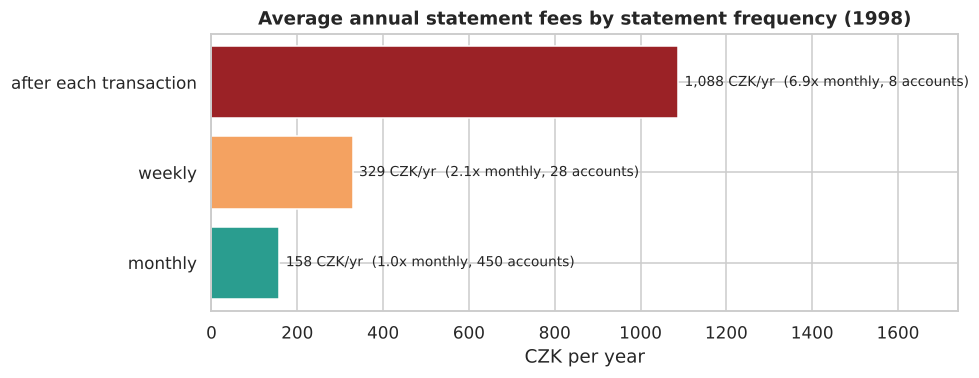

Accounts that went negative in 1998: 17 (3.4%)
Penalty interest paid: 2,928 CZK across 14 accounts


,count,mean,vs_monthly
statement_frequency,,,
monthly,450,158.4,1.0
weekly,28,328.9,2.1
after each transaction,8,1087.5,6.9


In [7]:
fees98 = (spend98[spend98["category"] == "Bank Fees"]
          .groupby("account_id")["amount"].sum()
          .rename("annual_fee").reset_index()
          .merge(accounts[["account_id", "statement_frequency"]]))
fee_by_freq = fees98.groupby("statement_frequency")["annual_fee"].agg(["count", "mean"]).sort_values("mean")
fee_by_freq["vs_monthly"] = fee_by_freq["mean"] / fee_by_freq.loc["monthly", "mean"]

penalty = spend98[spend98["category"] == "Penalty Interest"]
went_negative = y98[y98["balance"] < 0]["account_id"].nunique()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(fee_by_freq.index, fee_by_freq["mean"], color=["#2a9d8f", "#f4a261", "#9b2226"])
for y_, (v, n, r) in enumerate(zip(fee_by_freq["mean"], fee_by_freq["count"], fee_by_freq["vs_monthly"])):
    ax.text(v + 15, y_, f"{v:,.0f} CZK/yr  ({r:.1f}x monthly, {n} accounts)", va="center", fontsize=9)
ax.set(title="Average annual statement fees by statement frequency (1998)", xlabel="CZK per year",
       xlim=(0, fee_by_freq["mean"].max() * 1.6))
fig.tight_layout()
save(fig, "04_fees_by_frequency")
plt.show()

print(f"Accounts that went negative in 1998: {went_negative} ({went_negative / n_active:.1%})")
print(f"Penalty interest paid: {penalty['amount'].sum():,.0f} CZK across {penalty['account_id'].nunique()} accounts")
fee_by_freq.round(1)

## 6. Income vs. spending

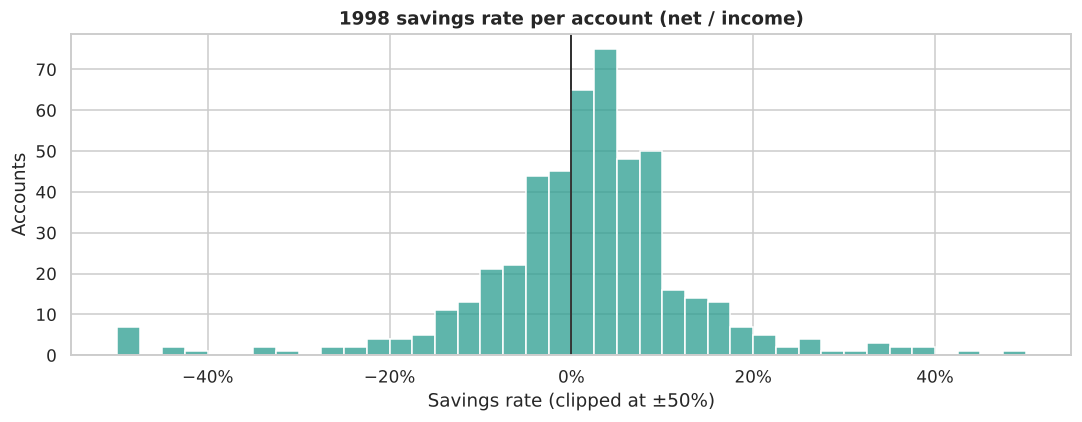

Accounts that spent more than they took in during 1998: 186 of 496 (38%)
Median shortfall among them: 7,634 CZK (~$236)
Median savings rate overall: 2.4%


In [8]:
income98 = y98[(y98["grp"] == "Income") & (y98["category"] != "Interest Earned")].groupby("account_id")["amount"].sum()
out98 = spend98.groupby("account_id")["amount"].sum()
bal = pd.concat([income98, out98], axis=1, keys=["income", "spending"]).fillna(0)
bal = bal[bal["income"] > 0]
bal["net"] = bal["income"] - bal["spending"]
bal["savings_rate"] = bal["net"] / bal["income"]
overspent = bal[bal["net"] < 0]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(bal["savings_rate"].clip(-0.5, 0.5), bins=40, ax=ax, color="#2a9d8f")
ax.axvline(0, color="black", lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="1998 savings rate per account (net / income)", xlabel="Savings rate (clipped at ±50%)",
       ylabel="Accounts")
fig.tight_layout()
save(fig, "05_savings_rate")
plt.show()

print(f"Accounts that spent more than they took in during 1998: {len(overspent)} of {len(bal)} ({len(overspent) / len(bal):.0%})")
print(f"Median shortfall among them: {-overspent['net'].median():,.0f} CZK (~{usd(-overspent['net'].median())})")
print(f"Median savings rate overall: {bal['savings_rate'].median():.1%}")

## 7. Forecasting monthly spending

The target is **average spending per account per month**. I compare forecasting methods with a **rolling backtest**: each month of 1998 is forecast using only data from before it (history starts in January 1995).

- **Last month** and **trailing 3-month average**: simple baselines
- **Same month last year** (seasonal naive): captures the January/June spikes
- **Same month last year x trend**: seasonal naive adjusted for year-over-year growth
- **Holt-Winters**: exponential smoothing with trend + 12-month seasonality

In [9]:
series = total_per_acct.copy()

def seasonal_trend(h):
    growth = h.iloc[-12:].sum() / h.iloc[-24:-12].sum()
    return h.iloc[-12] * growth

def holt_winters(h):
    model = ExponentialSmoothing(h.to_numpy(), trend="add", seasonal="add", seasonal_periods=12).fit()
    return model.forecast(1)[0]

methods = {
    "Last month": lambda h: h.iloc[-1],
    "Trailing 3-month avg": lambda h: h.iloc[-3:].mean(),
    "Same month last year": lambda h: h.iloc[-12],
    "Same month last year x trend": seasonal_trend,
    "Holt-Winters": holt_winters,
}
start = list(series.index).index(pd.Period("1998-01", "M"))
bt = backtest(series, methods, start=start)
scores = (bt.groupby("method")[["abs_error", "abs_pct_error"]].mean()
          .rename(columns={"abs_error": "MAE (CZK)", "abs_pct_error": "MAPE"})
          .sort_values("MAE (CZK)"))
scores.round(3)

,MAE (CZK),MAPE
method,,
Same month last year x trend,1170.411,0.066
Holt-Winters,1275.530,0.072
Same month last year,1376.924,0.076
Trailing 3-month avg,3777.179,0.219
Last month,4118.049,0.257


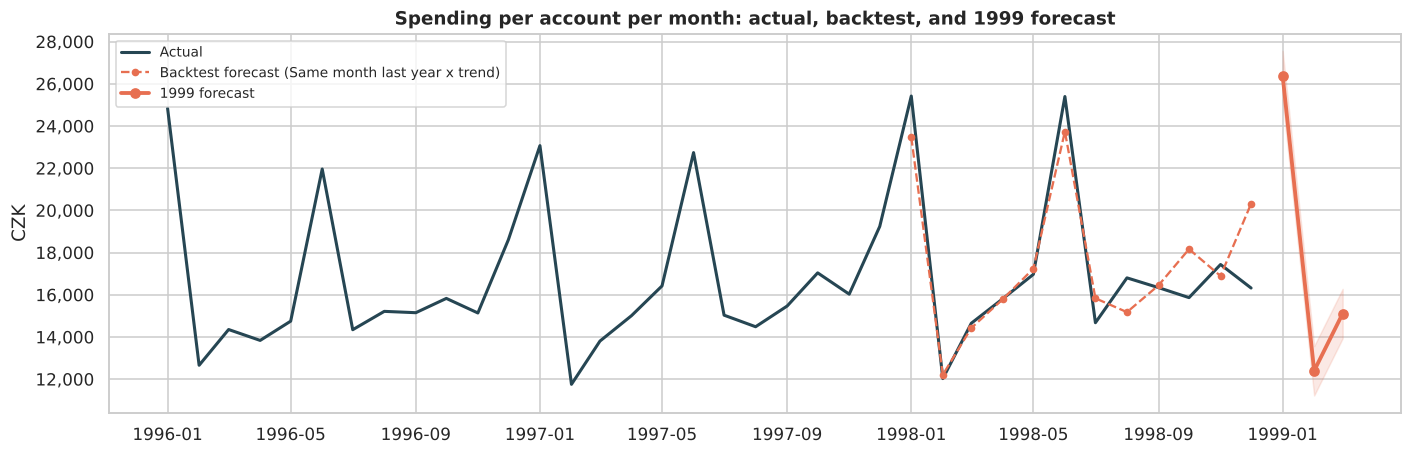

,forecast_czk_per_account
1999-01,26388.0
1999-02,12396.0
1999-03,15107.0


In [10]:
best = scores.index[0]
history = series.copy()
future = pd.period_range("1999-01", periods=3, freq="M")
fc = []
for p in future:
    v = methods[best](history)
    fc.append(v)
    history.loc[p] = v
fc = pd.Series(fc, index=future)
mae = scores.loc[best, "MAE (CZK)"]

fig, ax = plt.subplots(figsize=(13, 4.3))
b = bt[bt["method"] == best]
ax.plot(series.loc["1996-01":].index.to_timestamp(), series.loc["1996-01":], color="#264653", lw=2, label="Actual")
ax.plot(b["month"].apply(lambda p: p.to_timestamp()), b["forecast"], color="#e76f51", ls="--", marker="o",
        ms=4, label=f"Backtest forecast ({best})")
ax.plot(fc.index.to_timestamp(), fc.values, color="#e76f51", marker="o", lw=2.5, label="1999 forecast")
ax.fill_between(fc.index.to_timestamp(), fc - mae, fc + mae, color="#e76f51", alpha=0.15)
ax.yaxis.set_major_formatter(czk)
ax.set(title="Spending per account per month: actual, backtest, and 1999 forecast", ylabel="CZK")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "06_forecast")
plt.show()
fc.round(0).to_frame("forecast_czk_per_account")

## 8. Savings scenarios

Each scenario is tied to a finding above and measured against actual 1998 numbers for the 500-account sample.

In [11]:
monthly_fee = fee_by_freq.loc["monthly", "mean"]
switch = fees98[fees98["statement_frequency"] != "monthly"]
switch_savings = (switch["annual_fee"] - monthly_fee).clip(lower=0).sum()

# Overspending accounts: how much would a 10% cut in cash withdrawals close the gap?
cash98 = spend98[spend98["category"] == "Cash Withdrawals"].groupby("account_id")["amount"].sum()
o = overspent.join(cash98.rename("cash"), how="left").fillna({"cash": 0})
o["cut_10pct"] = 0.10 * o["cash"]
closed = (o["cut_10pct"] >= -o["net"]).mean()

scenarios = pd.DataFrame([
    {"scenario": "Switch weekly / per-transaction statements to monthly",
     "accounts": len(switch), "annual_savings_czk": switch_savings},
    {"scenario": "Keep a buffer to avoid negative balances (no penalty interest)",
     "accounts": penalty["account_id"].nunique(), "annual_savings_czk": penalty["amount"].sum()},
    {"scenario": "Overspending accounts: cut cash withdrawals by 10%",
     "accounts": len(o), "annual_savings_czk": o["cut_10pct"].sum()},
])
scenarios["per_account_czk"] = scenarios["annual_savings_czk"] / scenarios["accounts"]
scenarios["per_account_usd"] = scenarios["per_account_czk"] / CZK_PER_USD
print(f"A 10% cut in cash withdrawals would fully close the 1998 shortfall for {closed:.0%} of overspending accounts")
scenarios.round(0)

A 10% cut in cash withdrawals would fully close the 1998 shortfall for 57% of overspending accounts


,scenario,accounts,annual_savings_czk,per_account_czk,per_account_usd
0,Switch weekly / per-transaction statements to ...,36,12209.0,339.0,10.0
1,Keep a buffer to avoid negative balances (no p...,14,2928.0,209.0,6.0
2,Overspending accounts: cut cash withdrawals by...,186,2649565.0,14245.0,441.0


## 9. Key findings

1. **The tracker categorized 100% of 117,560 real transactions** from 500 accounts by translating the bank's Czech codes into 12 English categories in 5 groups.
2. **Cash ruled 1990s Czech banking.** In 1998 the average account spent **17,308 CZK/month (~$536)**: 74% as cash withdrawals, 17% on household bills, and under 1% by card.
3. **Spending is seasonal.** January and June run **53% above** other months, December card purchases are **4.5x** a normal month, and household bills per account rose **18%** from 1995 to 1998.
4. **Spending spikes are common and mostly cash.** **60% of accounts** had at least one month where spending doubled (+10,000 CZK or more). The median spike was +24,300 CZK (~$752), 38% of spikes landed in January or June, and **98% were driven by cash withdrawals**.
5. **Statement frequency drives fees.** Weekly statements cost **2.1x** and per-transaction statements **6.9x** what monthly statements cost. 17 accounts went negative and 14 paid penalty interest.
6. **38% of accounts spent more than they took in** during 1998 (median shortfall 7,634 CZK, ~$236). The median savings rate was just 2.4%.
7. **Seasonality makes forecasting accurate.** "Same month last year x trend" had the lowest backtest error (**6.6% MAPE** vs 25.7% for "last month") and predicts another January spike in 1999.
8. **Savings recommendations:** switching to monthly statements saves the affected accounts ~339 CZK/year each, and a **10% cut in cash withdrawals would fully close the shortfall for 57% of overspending accounts**.

**Limitations:** this is 1990s data from one Czech bank, so the patterns describe that market, not today's. Cash withdrawals and transfers have no purpose code, so what that money was spent on can't be broken down further. Results come from a random 500-account sample of the bank's 4,500 accounts. The data ends in December 1998, so that month's statement fees aren't included.